# 01. Tổng quan bộ dữ liệu

## 1. Khởi tạo thư viện và đọc dữ liệu

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/data_config.yaml').is_file())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data.dataset_loader import DatasetLoader
from src.data.vessel_dataset import VesselDataset
from src.data.encounter_dataset import EncounterDataset
from src.data.tensor_verification import verify, FEATURES
loader = DatasetLoader()
splits = {name: loader.load_split(name) for name in ('train', 'validation')}
plt.rcParams['figure.dpi'] = 100


## 2. Cấu trúc và quy mô bộ dữ liệu

In [2]:
contract = verify()
print('Version:', contract['dataset_version'], '| Lock:', contract['lock_status'], '| Checksum:', contract['checksum']['status'], contract['checksum']['files_verified'], 'files')
display(pd.DataFrame([{'split':k, 'encounters':v['encounters'], 'vessels':v['vessels'], 'records':loader.config['splits'][k]['records'], 'X shape':tuple(loader.load_split(k).X.shape)} for k,v in contract['splits'].items()]).set_index('split'))
print('Số thuộc tính schema:', len(json.loads((loader.root/'schemas/schema.json').read_text(encoding='utf-8'))['columns']))
display(pd.DataFrame(loader.lock['source_counts']).fillna(0).astype(int))

Version: final_dataset_1.0 | Lock: READY_AND_LOCKED | Checksum: PASS 93 files


,encounters,vessels,records,X shape
split,,,,
train,1440,2880,72000,"(2880, 10, 4)"
validation,835,1670,41750,"(1670, 10, 4)"
test,1320,2640,66000,"(2640, 10, 4)"


Số thuộc tính schema: 39


,train,validation,test
yang_lei,1440,240,720
real_ais,0,295,300
synthetic_ais,0,300,300


## 3. Phân bố nguồn, nhãn và tình huống


 data_source


data_source,augmented_real_ais_kattegat_v3,real_ais_kattegat_v3,yang_lei,yanglei
package,,,,
train,0,0,1440,0
validation,300,295,0,240



 high_risk_label


high_risk_label,0,1
package,,
train,689,751
validation,410,425



 scenario


scenario,crossing_port,crossing_starboard,head_on,other_or_uncertain,overtaking
package,,,,,
train,354,460,320,0,306
validation,202,230,135,60,208



 difficulty


difficulty,Không có / không áp dụng
package,
train,1440
validation,835



 method


method,Không có / không áp dụng,combined,course_modification,spatial_translation,speed_scaling,time_shift
package,,,,,,
train,1440,0,0,0,0,0
validation,535,74,66,120,7,33


high_risk_label,negative,positive
package,,
train,0.478472,0.521528
validation,0.491018,0.508982


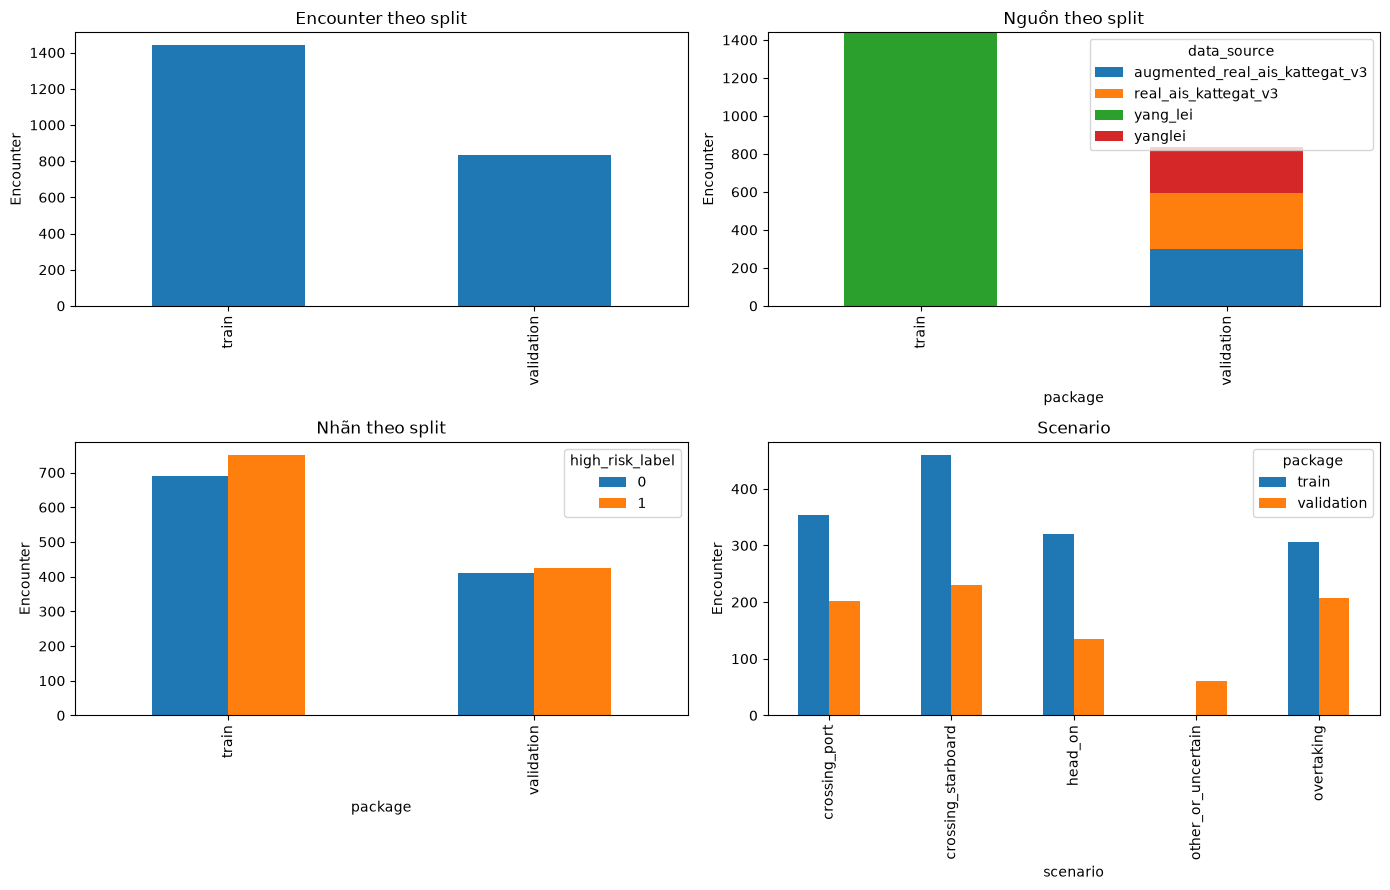

In [3]:
meta = pd.concat([s.metadata.assign(package=name) for name,s in splits.items()], ignore_index=True)
for field in ('data_source','high_risk_label','scenario','difficulty','method'):
    print('\n',field)
    display(pd.crosstab(meta['package'],meta[field].fillna('Không có / không áp dụng')))
labels = pd.crosstab(meta['package'],meta['high_risk_label'])
display(labels.div(labels.sum(axis=1),axis=0).rename(columns={0:'negative',1:'positive'}))
fig, ax = plt.subplots(2,2,figsize=(14,9))
pd.Series({k:len(s.encounters) for k,s in splits.items()}).plot.bar(ax=ax[0,0],title='Encounter theo split')
pd.crosstab(meta.package,meta.data_source).plot.bar(stacked=True,ax=ax[0,1],title='Nguồn theo split')
labels.plot.bar(ax=ax[1,0],title='Nhãn theo split')
pd.crosstab(meta.scenario.fillna('Không có'),meta.package).plot.bar(ax=ax[1,1],title='Scenario')
for a in ax.flat: a.set_ylabel('Encounter')
plt.tight_layout(); plt.show()

## 4. Thống kê đặc trưng AIS và chất lượng dữ liệu

LAT                                                         \
              count    mean    std     min     25%     50%     75%     max   
split                                                                        
train       28800.0  37.800  0.020  37.740  37.786  37.800  37.814  37.856   
validation  16700.0  51.707  8.846  37.744  37.825  57.297  57.684  57.974   

                LON           ...     SOG              COG                    \
              count     mean  ...     75%     max    count     mean      std   
split                         ...                                              
train       28800.0 -122.420  ...  15.368  22.976  28800.0  179.664  104.153   
validation  16700.0  -27.161  ...  12.738  26.800  16700.0  184.644  100.650   

                                                       
              min      25%      50%      75%      max  
split                                                  
train       0.015   91.289  180.797  270.562  359.993  
validation  0.000  102.612  177.000  271.657  359.957  

[2 rows x 32 columns]

,LAT,LON,SOG,COG
split,,,,
train,0,0,0,0
validation,0,0,0,0


,invalid_LAT,invalid_LON,invalid_SOG,invalid_COG
split,,,,
train,0,0,0,0
validation,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,2880.0,10.0,0.0,10.0,10.0,10.0,10.0,10.0
validation,1670.0,10.0,0.0,10.0,10.0,10.0,10.0,10.0


,status,rows,vessel_groups,utc
train,PASS,72000,2880,True
validation,PASS,41750,1670,True


train khoảng cách anchor nm: {'count': 1440.0, 'mean': 1.177, 'std': 0.605, 'min': 0.017, '25%': 0.717, '50%': 1.114, '75%': 1.559, 'max': 3.669}
validation khoảng cách anchor nm: {'count': 835.0, 'mean': 1.816, 'std': 0.926, 'min': 0.061, '25%': 1.018, '50%': 1.777, '75%': 2.824, 'max': 3.43}


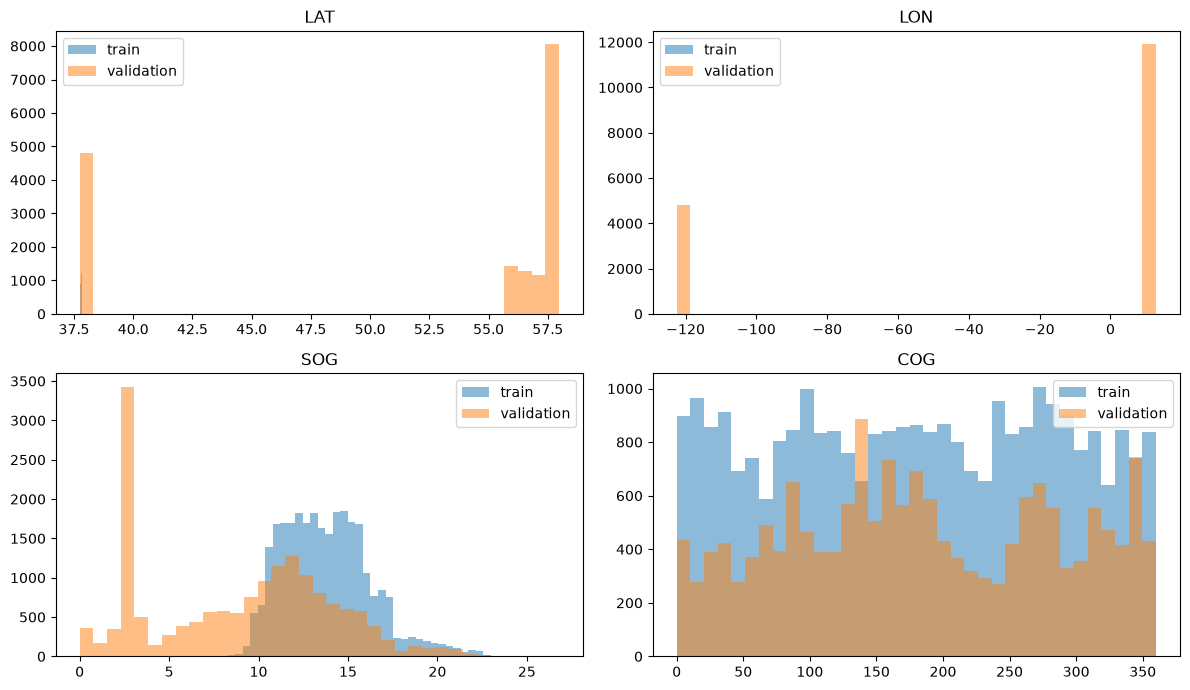

In [4]:
history = []
for name,s in splits.items():
    frame = pd.read_parquet(loader.root/name/'data'/loader.config['splits'][name]['data'])
    h = frame.loc[frame.is_history, ['LAT','LON','SOG','COG','encounter_id','vessel','relative_minute']].copy(); h['split']=name; history.append(h)
hist = pd.concat(history,ignore_index=True)
display(hist.groupby('split')[['LAT','LON','SOG','COG']].describe().round(3))
display(hist.groupby('split')[['LAT','LON','SOG','COG']].apply(lambda x:x.isna().sum()))
invalid = hist.assign(invalid_LAT=~hist.LAT.between(-90,90), invalid_LON=~hist.LON.between(-180,180), invalid_SOG=(hist.SOG<0), invalid_COG=~hist.COG.between(0,360))
display(invalid.groupby('split')[['invalid_LAT','invalid_LON','invalid_SOG','invalid_COG']].sum())
display(hist.groupby(['split','encounter_id','vessel']).size().groupby(level=0).describe())
display(pd.DataFrame({k:v['timestamp'] for k,v in contract['splits'].items() if k != 'test'}).T)
for name,s in splits.items(): print(name, 'khoảng cách anchor nm:', pd.Series(np.linalg.norm(s.anchors[:,0]-s.anchors[:,1],axis=1)).describe().round(3).to_dict())
fig, ax=plt.subplots(2,2,figsize=(12,7))
for a,col in zip(ax.flat,['LAT','LON','SOG','COG']):
    for name,g in hist.groupby('split'): a.hist(g[col].dropna(), bins=35, alpha=.5, label=name)
    a.set_title(col); a.legend()
plt.tight_layout(); plt.show()

## 5. Trực quan hóa quỹ đạo tàu

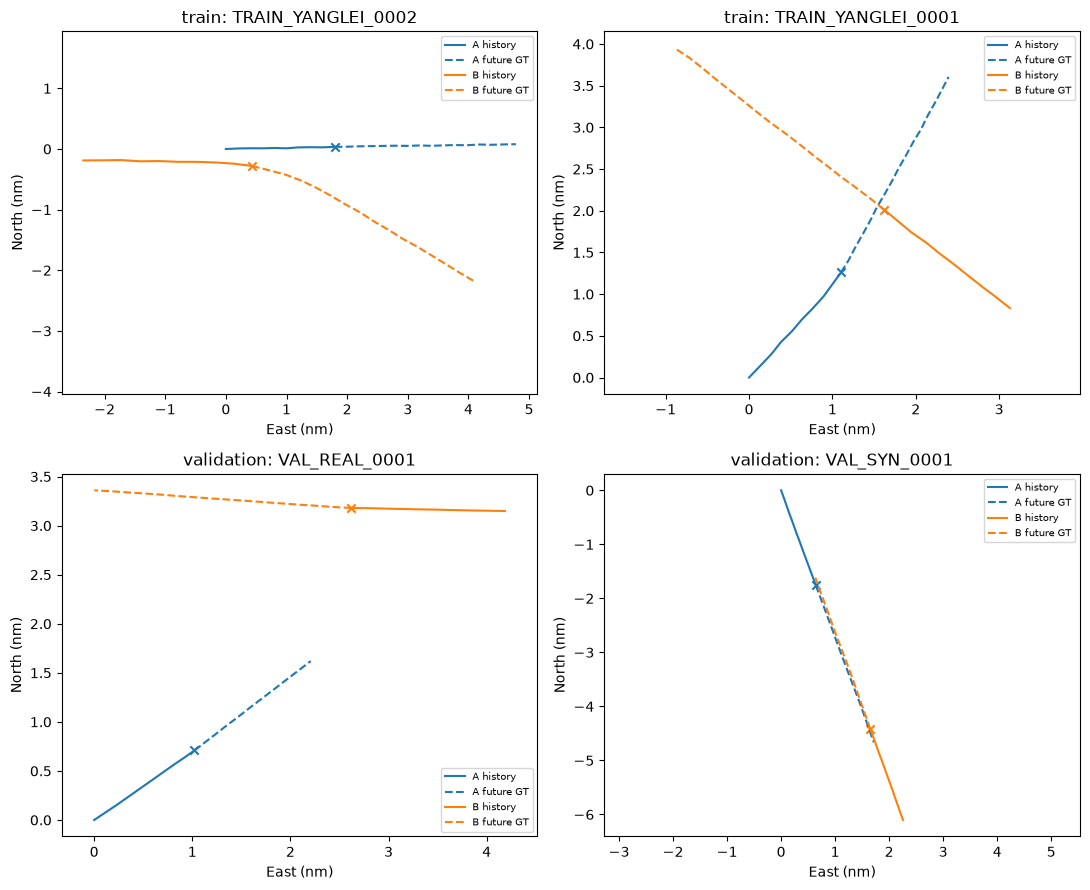

In [5]:
criteria = [('train','yang',0),('train','yang',1),('validation','real_ais',0),('validation','augmented',1)]
fig, axes = plt.subplots(2,2,figsize=(11,9))
for ax,(name,source,label) in zip(axes.flat,criteria):
    s=splits[name]; m=s.metadata
    mask=m.data_source.str.contains(source,case=False,na=False) & (m.high_risk_label==label)
    if source == 'real_ais': mask &= ~m.data_source.str.contains('augmented',case=False,na=False)
    ids=np.flatnonzero(mask.to_numpy())
    if not len(ids): ax.set_title('Không có mẫu phù hợp'); continue
    i=int(ids[0]); item=EncounterDataset(s)[i]; x=item['model_input']['X'].numpy(); a=item['model_input']['anchors_EN_nm'].numpy(); y=item['ground_truth']['target_EN_nm'].numpy()
    for side,color in enumerate(('tab:blue','tab:orange')):
        pos=x[side,:,:2]+a[side]; ax.plot(pos[:,0],pos[:,1],color=color,label=f"{'AB'[side]} history"); ax.plot(np.r_[a[side,0],y[side,:,0]],np.r_[a[side,1],y[side,:,1]],'--',color=color,label=f"{'AB'[side]} future GT"); ax.scatter(*a[side],color=color,marker='x')
    ax.set(title=f"{name}: {item['encounter_id']}",xlabel='East (nm)',ylabel='North (nm)'); ax.legend(fontsize=7); ax.axis('equal')
plt.tight_layout(); plt.show()

## 6. Lưu ý về dữ liệu

Dữ liệu được xây dựng và khóa trước khi lập repository. Train chỉ gồm Yang Lei; Validation bổ sung AIS thực và tổng hợp. Nhãn là proxy, có thể có phụ thuộc giữa các encounter và không xác nhận an toàn thực tế. Test chỉ được mô tả cấu trúc.